# Question Bank Distribution

Bar chart showing the number of prohibited questions per protected-class
category, ranked from most to fewest. Referenced as `\autoref{fig:question_dist}`
in Section 3.2 (Question Bank).

**Output:** `latex/figures/question_bank_dist.pdf`

In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('HIREWATCH_ROOT', '.')).resolve()
FIG_DIR = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from analysis.categories import load_categories, default_bank_path

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'DejaVu Serif'],
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

Total prohibited questions: 50
  Disability    15 (30%)
  Religion      11 (22%)
  Sex/Marital    7 (14%)
  Genetic        6 (12%)
  Nat Origin     6 (12%)
  Pregnancy      2 (4%)
  Race           2 (4%)
  Color          1 (2%)


/tmp/ipykernel_1933564/602619853.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Purples')


Saved: ./latex/figures/question_bank_dist.pdf


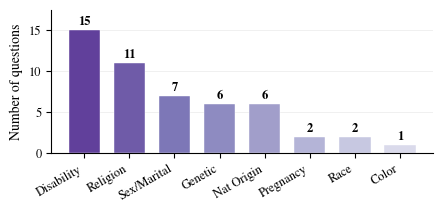

In [2]:
# Load categories from the canonical CSV, sort by count descending
categories = load_categories(default_bank_path(ROOT))
sorted_cats = sorted(categories, key=lambda x: len(x[1]), reverse=True)
names  = [name for name, ids in sorted_cats]
counts = [len(ids) for _, ids in sorted_cats]
total  = sum(counts)

print(f'Total prohibited questions: {total}')
for n, c in zip(names, counts):
    print(f'  {n:<12} {c:>3} ({c/total*100:.0f}%)')

# Pastel purple gradient: darkest for most numerous, lightest for fewest
import matplotlib.cm as cm

cmap = cm.get_cmap('Purples')
colors = [cmap(0.80 - i * 0.55 / max(len(names) - 1, 1)) for i in range(len(names))]

fig, ax = plt.subplots(figsize=(4.5, 2.2))

x = np.arange(len(names))
bars = ax.bar(x, counts, color=colors, edgecolor='white', linewidth=0.3,
              width=0.7)

# Annotate each bar with the count
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(c), ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha='right')
ax.set_ylabel('Number of questions')
ax.set_ylim(0, max(counts) + 2.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#cccccc', linewidth=0.4, alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
out = FIG_DIR / 'question_bank_dist.pdf'
fig.savefig(out, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()